In [ ]:
# # Run after NLCD clipped rasters are created

# import geopandas as gpd
# import rasterio
# from rasterio import features
# import numpy as np
# import pandas as pd
# from scipy.ndimage import distance_transform_edt
# import os
# import gc


# # 1. Configuration & Paths
# nwi_folder = "/kaggle/input/datasets/maanav0114/ambystoma-sdm-data/"
# master_raster_path = "/kaggle/working/land_cover_clipped.tiff"  # Must be EPSG:5070
# output_distance_raster = "/kaggle/working/ambystoma_wetland_distance.tiff"

# # Your downloaded GeoPackage files
# state_files = [
#     "IL_geopackage_wetlands.gpkg",
#     "IN_geopackage_wetlands.gpkg",
#     "OH_geopackage_wetlands.gpkg",
#     "MI_geopackage_wetlands.gpkg",
#     "KY_geopackage_wetlands.gpkg",
#     "PA_geopackage_wetlands.gpkg",
#     "WV_geopackage_wetlands.gpkg",
# ]  # Update this list to exactly match your downloaded OH, MI, IN, PA, KY, WV filenames


# # 2. Extract Master Grid Metadata
# with rasterio.open(master_raster_path) as src:
#     master_meta      = src.meta.copy()
#     master_transform = src.transform
#     master_shape     = src.shape  # (height, width)

#     # Force float32 for continuous distance calculations
#     master_meta.update(dtype=rasterio.float32, nodata=-9999.0)

# print(f"Master Grid loaded. Shape: {master_shape}, CRS: {src.crs}")


# # 3. Iterative Vector Processing (Optimized for RAM)
# palustrine_polygons = []

# for file in state_files:

#     # Skip if not one of your 6 target states (adjust list above as needed)
#     if not file.startswith(("OH", "MI", "IN", "PA", "KY", "WV")):
#         continue

#     file_path = os.path.join(nwi_folder, file)
#     print(f"Processing {file}...")

#     # Read ONLY Palustrine wetlands directly from disk using pyogrio SQL pushdown
#     gdf = gpd.read_file(
#         file_path,
#         engine="pyogrio",
#         where="ATTRIBUTE LIKE 'P%'"
#     )

#     # Reproject to EPSG:5070 to match the NLCD master grid
#     if gdf.crs != "EPSG:5070":
#         gdf = gdf.to_crs("EPSG:5070")

#     # Heal invalid geometries (fixes topology errors that crash rasterization)
#     gdf['geometry'] = gdf.geometry.buffer(0)

#     # Keep only the geometry column to save memory
#     palustrine_polygons.append(gdf[['geometry']])

#     # Force garbage collection to clear the un-buffered GeoDataFrame from RAM
#     del gdf
#     gc.collect()


# # 4. Merge State Polygons
# print("Merging all state geometries...")

# all_wetlands = pd.concat(palustrine_polygons, ignore_index=True)
# all_wetlands = gpd.GeoDataFrame(all_wetlands, geometry='geometry', crs="EPSG:5070")

# # Clear the list from memory
# del palustrine_polygons
# gc.collect()


# # 5. Rasterize the Polygons
# print("Rasterizing wetland polygons...")

# # Burn a '1' where a wetland exists
# geom_value_pairs = [(geom, 1) for geom in all_wetlands.geometry]

# wetland_mask = features.rasterize(
#     shapes=geom_value_pairs,
#     out_shape=master_shape,
#     transform=master_transform,
#     fill=0,
#     dtype=np.uint8
# )

# # Clear the massive vector dataframe from memory before doing matrix math
# del all_wetlands, geom_value_pairs
# gc.collect()


# # 6. Calculate Euclidean Distance
# print("Calculating continuous distance gradient...")

# # Invert mask: wetlands become 0 (target), land becomes 1
# inverse_mask = (wetland_mask == 0).astype(int)

# # Free up the original mask memory
# del wetland_mask
# gc.collect()

# # Calculate pixel distance to the nearest 0 (wetland)
# distance_grid = distance_transform_edt(inverse_mask)

# # Multiply by 30 to convert pixel distance into true distance in meters (EPSG:5070 unit)
# distance_grid = (distance_grid * 30.0).astype(np.float32)


# # 7. Save to Disk
# print("Saving output distance raster...")

# with rasterio.open(output_distance_raster, 'w', **master_meta) as dest:
#     dest.write(distance_grid, 1)

# print("Done! The distance feature is perfectly aligned and ready for extraction.")


In [1]:
import geopandas as gpd
import pyogrio
import rasterio
from rasterio import features
from rasterio.windows import Window, transform as window_transform
import numpy as np
import subprocess
import os
import gc
import resource


# Peak resident memory of this process, in MiB (ru_maxrss is KiB on Linux).
# Kaggle OOM-kills the kernel without a Python traceback, so log this after
# every state to see which one pushes the run over the limit.
def peak_rss_mib():
    return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024


def pixel_window(bounds, transform, shape):
    """Integer pixel window covering `bounds`, clamped to the raster shape."""
    left, bottom, right, top = bounds
    inv = ~transform
    col_a, row_a = inv * (left, top)
    col_b, row_b = inv * (right, bottom)

    col_0 = max(0, min(int(np.floor(min(col_a, col_b))), shape[1] - 1))
    row_0 = max(0, min(int(np.floor(min(row_a, row_b))), shape[0] - 1))
    col_1 = max(0, min(int(np.ceil(max(col_a, col_b))), shape[1]))
    row_1 = max(0, min(int(np.ceil(max(row_a, row_b))), shape[0]))

    return Window(col_0, row_0, col_1 - col_0, row_1 - row_0)


# 1. Configuration & Paths
nwi_folder = "/kaggle/input/datasets/maanav0114/ambystoma-sdm-data/"
master_raster_path = "/kaggle/input/datasets/maanav0114/ambystoma-sdm-data/land_cover_clipped_reproj.tiff"
temp_mask_raster = "/kaggle/working/temp_wetland_mask.tif"
output_distance_raster = "/kaggle/working/wetland_distance.tiff"

# Polygons read and rasterized per step. Peak RAM scales with this, not with the
# size of a state: burning one IN-sized state in a single call needed ~7 GiB,
# while 20k polygons at a time needs well under 1 GiB.
CHUNK_SIZE = 20_000

state_files = [
    "IN_geopackage_wetlands.gpkg",
    "OH_geopackage_wetlands.gpkg",
    "MI_geopackage_wetlands.gpkg",
    "KY_geopackage_wetlands.gpkg",
    "PA_geopackage_wetlands.gpkg",
    "WV_geopackage_wetlands.gpkg",
]


# 2. Extract Master Grid Metadata & EXACT CRS
with rasterio.open(master_raster_path) as src:
    master_meta      = src.meta.copy()
    master_transform = src.transform
    master_shape     = src.shape  # (44027, 45094)
    master_crs       = src.crs    # Use the EXACT CRS from the master raster!

print(f"Master Grid loaded. Shape: {master_shape}")

mask_meta = master_meta.copy()
mask_meta.update(
    dtype=rasterio.uint8,
    nodata=0,
    count=1,
    compress="lzw",
    tiled=True,       # window writes stay cheap on a tiled GeoTIFF
    blockxsize=512,
    blockysize=512,
)


# 3. Burn every state into one shared mask, in chunks, window by window.
# No full-extent array is ever held in RAM: each chunk is rasterized into just
# its own bounding window and written back, preserving pixels burned earlier.
# "w+" (not "w") because every chunk reads its window back before overwriting it.
with rasterio.open(temp_mask_raster, "w+", **mask_meta) as dest:

    for file in state_files:

        file_path = os.path.join(nwi_folder, file)

        if not os.path.exists(file_path):
            print(f"Skipping {file} (not found)...")
            continue

        # Extract state prefix (e.g., "IN") to target the "<ST>_Wetlands" layer
        state_abbr   = file.split("_")[0]
        target_layer = f"{state_abbr}_Wetlands"

        # Fallback check in case a state names its layer slightly differently
        available_layers = [lyr[0] for lyr in pyogrio.list_layers(file_path)]

        if target_layer not in available_layers:
            # Pick the layer that ends with '_Wetlands'
            matches      = [lyr for lyr in available_layers if lyr.endswith("_Wetlands")]
            target_layer = matches[0] if matches else available_layers[0]

        print(f"Processing {file} (Layer: {target_layer})...")

        burned = 0
        chunks = 0
        offset = 0

        while True:

            # Palustrine wetlands only. The WHERE clause is applied before
            # paging, so skip_features/max_features walk the filtered set with
            # no gaps and no duplicates.
            gdf = gpd.read_file(
                file_path,
                layer=target_layer,
                engine="pyogrio",
                where="ATTRIBUTE LIKE 'P%'",
                columns=[],  # Only load geometries, skip attribute columns to save RAM
                skip_features=offset,
                max_features=CHUNK_SIZE,
            )

            if len(gdf) == 0:
                break

            offset += CHUNK_SIZE
            chunks += 1

            # Drop null geometries so total_bounds cannot come back as NaN
            gdf = gdf[gdf.geometry.notna()]

            if gdf.empty:
                del gdf
                gc.collect()
                continue

            # Reproject to match the exact master raster CRS (AEA WGS84)
            if gdf.crs != master_crs:
                gdf = gdf.to_crs(master_crs)

            # Burn only into this chunk's window, keeping what is already there
            win = pixel_window(gdf.total_bounds, master_transform, master_shape)

            if win.width > 0 and win.height > 0:

                tile = dest.read(1, window=win)

                features.rasterize(
                    shapes=((geom, 1) for geom in gdf.geometry if geom is not None),
                    out=tile,
                    transform=window_transform(win, master_transform),
                    merge_alg=rasterio.enums.MergeAlg.replace,
                    dtype=np.uint8,
                )

                dest.write(tile, 1, window=win)
                del tile

            burned += len(gdf)
            del gdf
            gc.collect()

        print(f"  -> Burned {burned} polygons in {chunks} chunks | "
              f"peak RAM {peak_rss_mib():.0f} MiB")

print(f"Mask written: {temp_mask_raster} "
      f"({os.path.getsize(temp_mask_raster) / 2**20:.0f} MiB on disk)")
print(f"Peak RAM after mask write: {peak_rss_mib():.0f} MiB")


# 4. Calculate Euclidean Distance Out-of-Core via GDAL
print("Calculating continuous distance in meters using gdal_proximity...")

# -values 1:      measure distance to pixels with value 1 (wetlands)
# -distunits GEO: automatically multiplies pixel distance by 30m (georeferenced units)
# -ot Float32:    keeps output in 32-bit float instead of 64-bit float
cmd = [
    "gdal_proximity.py",
    temp_mask_raster,
    output_distance_raster,
    "-values", "1",
    "-distunits", "GEO",
    "-ot", "Float32",
    "-co", "COMPRESS=LZW",
    "-co", "BIGTIFF=YES",
]

subprocess.run(cmd, check=True)
print(f"Peak RAM after gdal_proximity: {peak_rss_mib():.0f} MiB")

# Clean up temporary mask file
os.remove(temp_mask_raster)

print(f"Done! Saved aligned distance raster to {output_distance_raster}")


Master Grid loaded. Shape: (44027, 45094)
Processing IN_geopackage_wetlands.gpkg (Layer: IN_Wetlands)...
  -> Burned 361558 polygons in 19 chunks | peak RAM 1331 MiB
Processing OH_geopackage_wetlands.gpkg (Layer: OH_Wetlands)...
  -> Burned 357946 polygons in 18 chunks | peak RAM 2585 MiB
Processing MI_geopackage_wetlands.gpkg (Layer: MI_Wetlands)...
  -> Burned 1005746 polygons in 51 chunks | peak RAM 2585 MiB
Processing KY_geopackage_wetlands.gpkg (Layer: KY_Wetlands)...
  -> Burned 289845 polygons in 15 chunks | peak RAM 2585 MiB
Processing PA_geopackage_wetlands.gpkg (Layer: PA_Wetlands)...
  -> Burned 237660 polygons in 12 chunks | peak RAM 2585 MiB
Processing WV_geopackage_wetlands.gpkg (Layer: WV_Wetlands)...
  -> Burned 120721 polygons in 7 chunks | peak RAM 3178 MiB
Mask written: /kaggle/working/temp_wetland_mask.tif (20 MiB on disk)
Peak RAM after mask write: 3178 MiB
Calculating continuous distance in meters using gdal_proximity...
Peak RAM after gdal_proximity: 3178 MiB
Don

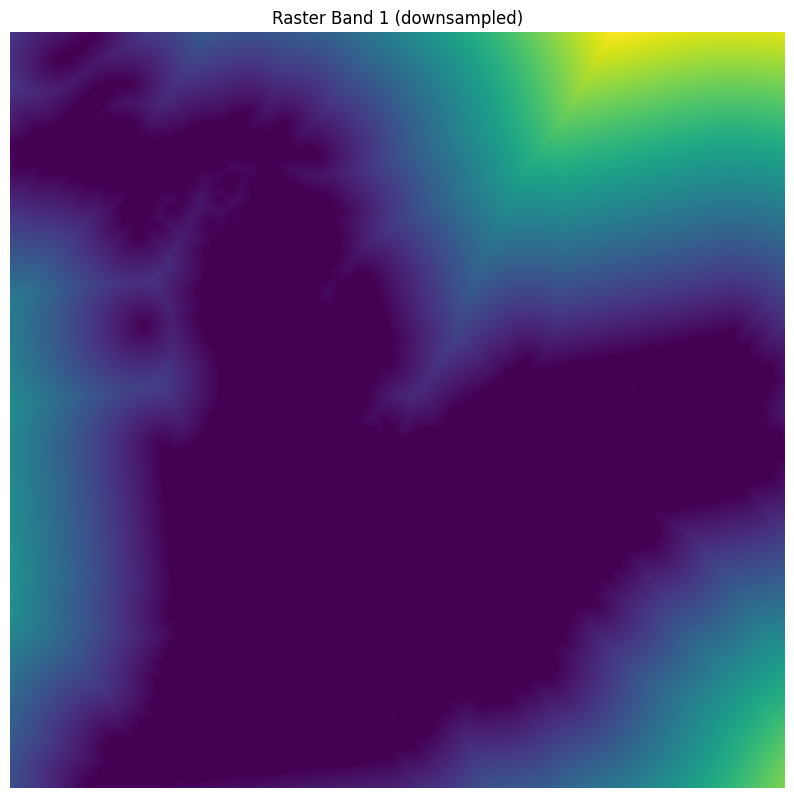

In [2]:
from rasterio.enums import Resampling
import matplotlib.pyplot as plt



max_size = 1500
with rasterio.open('/kaggle/working/wetland_distance.tiff') as src:
    scale = min(max_size / src.width, max_size / src.height)
    width = max(1, int(src.width * scale))
    height = max(1, int(src.height * scale))

    image = src.read(
        1,
        out_shape=(height, width),
        resampling=Resampling.average,
        masked=True,
    )

fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(image, cmap='viridis')
ax.set_title('Raster Band 1 (downsampled)')
ax.axis('off')
plt.show()